In [33]:
%matplotlib inline

import sys
from pathlib import Path

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
for p in (CODE_DIR, CODE_DIR / "scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from environments.gridworld import GridNavi
from detect import Detect

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from matplotlib.patches import Rectangle
from IPython.display import display

# Sparse trained MDP (logs_gridworld): SARS under data/gridworld_sparse/task_dist{id}/
# (separate from the earlier dense probe data under data/gridworld/)
DATA_ROOT = CODE_DIR / "data" / "gridworld_sparse"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("CODE_DIR", CODE_DIR)
print("DATA_ROOT", DATA_ROOT)

ACTION_NAMES = {0: "noop", 1: "up", 2: "right", 3: "down", 4: "left"}

CODE_DIR /home/mahesh/hypex
DATA_ROOT /home/mahesh/hypex/data/gridworld_sparse


In [34]:
# defining one task distribution by defining an array of possible goals -

def goal_positions(option, NUM_CELLS):
    if option == 1:
        # 4 goal choices, all in top right corner
        pos = [(NUM_CELLS-1, NUM_CELLS-1), (NUM_CELLS-1, NUM_CELLS-2), (NUM_CELLS-2, NUM_CELLS-1), (NUM_CELLS-2, NUM_CELLS-2)]
    elif option == 2:
        # slightly more spread out
        pos = [(NUM_CELLS//2, NUM_CELLS//2), (NUM_CELLS-1, NUM_CELLS//2), (NUM_CELLS//2, NUM_CELLS-1), (NUM_CELLS-1, NUM_CELLS-1)]
    elif option == 3:
        # goals are all 4 corners
        pos = [(0, 0), (0, NUM_CELLS-1), (NUM_CELLS-1, 0), (NUM_CELLS-1, NUM_CELLS-1)]
    elif option == 4:
        # 4 goal choices in the bottom left corner
        pos = [(0, 0), (0, 1), (1, 0), (1, 1)]
    elif option == 5:
        # 4 goal choices in the top left corner
        pos = [(0, NUM_CELLS-1), (0, NUM_CELLS-2), (1, NUM_CELLS-1), (1, NUM_CELLS-2)]
    elif option == 6:
        # 4 goal choices in the bottom right corner
        pos = [(NUM_CELLS-1, 0), (NUM_CELLS-1, 1), (NUM_CELLS-2, 0), (NUM_CELLS-2, 1)]
    return pos


In [25]:
# Match the trained sparse env (GridNavi-TaskDist{k}-v0 in logs_gridworld):
# 6x6, sparse reward, H=20, uniform random start.
NUM_CELLS = 6
MAX_STEPS = 20
N = NUM_CELLS * NUM_CELLS * MAX_STEPS
SEED = 42


def collect_tuples(task_dists, seed=SEED, distance_reward=False):
    """Collect SARS for the trained sparse GridNavi task dists.

    Saves under data/gridworld_sparse/task_dist{id}/goal_x_y.npy.
    MDP: num_cells=6, num_steps=20, sparse reward (+1 at goal, else -0.1),
    every start cell enumerated (uniform start distribution, as in training).

    distance_reward=False → sparse (trained setting; default)
    distance_reward=True  → dense Manhattan (earlier probe only)
    """
    rng = np.random.default_rng(seed)
    for dist_id, task_dist in task_dists.items():
        out_dir = DATA_ROOT / f"task_dist{dist_id}"
        out_dir.mkdir(parents=True, exist_ok=True)

        for task in task_dist:
            sar_rows = []
            for j in range(NUM_CELLS):
                for k in range(NUM_CELLS):
                    env = GridNavi(
                        num_cells=NUM_CELLS,
                        num_steps=MAX_STEPS,
                        distance_reward=distance_reward,
                        starting_state=(j, k),
                        possible_goals=task_dist,
                    )
                    env.reset_task(task=task)
                    obs, _ = env.reset()

                    for _ in range(MAX_STEPS):
                        action = int(rng.integers(env.action_space.n))
                        next_obs, reward, terminated, truncated, info = env.step(action)
                        sar_rows.append(
                            [obs[0], obs[1], action, reward, next_obs[0], next_obs[1]]
                        )
                        obs = next_obs
                        if terminated or truncated:
                            obs, _ = env.reset()

            sar = np.array(sar_rows[:N])  # (N, 6): [x, y, action, reward, x', y']
            path = out_dir / f"goal_{task[0]}_{task[1]}.npy"
            np.save(path, sar)
            print(f"dist {dist_id} goal={task} → {path.name} shape={sar.shape}")


def mean_pairwise_cosine_distance(embeddings):
    """Mean pairwise cosine distance (1 - cos) after L2-normalizing each embedding.

    Already an average over pairs (not a sum), so more tasks do not mechanically
    inflate the score — but unequal task counts still make cross-env comparison
    imperfect; use mean_pairwise_matched(..., PAIRWISE_SUBSET_SIZE) for that.
    """
    E = np.stack([np.asarray(e).ravel() for e in embeddings], axis=0)
    norms = np.linalg.norm(E, axis=1, keepdims=True)
    E = E / np.clip(norms, 1e-12, None)
    cos_dists = [
        1.0 - float(np.dot(E[i], E[j]))
        for i in range(len(E))
        for j in range(i + 1, len(E))
    ]
    return float(np.mean(cos_dists)) if cos_dists else float("nan")


def evenly_spaced_indices(n, k):
    """k indices in [0, n) including endpoints (same coverage idea as linspace)."""
    if k >= n:
        return list(range(n))
    return sorted({int(round(i)) for i in np.linspace(0, n - 1, k)})


def mean_pairwise_matched(embeddings, subset_size):
    """Fair mean pairwise when TDs have different #tasks.

    If n <= subset_size: ordinary mean pairwise.
    If n > subset_size: average of mean-pairwise over *all* subsets of size
    subset_size (U-statistic). Use the same subset_size in exp2 and exp9
    (default 4 = #goals per GridNavi TD).
    """
    embs = [np.asarray(e).ravel() for e in embeddings]
    n = len(embs)
    if n <= subset_size:
        return mean_pairwise_cosine_distance(embs)
    return float(np.mean([
        mean_pairwise_cosine_distance(list(subset))
        for subset in combinations(embs, subset_size)
    ]))


def mean_pairwise_wte(dist_id, goals):
    """Mean pairwise cosine distance of WTE/LWE embeddings within one task dist."""
    out_dir = DATA_ROOT / f"task_dist{dist_id}"
    embeddings = []
    for goal in goals:
        sar = np.load(out_dir / f"goal_{goal[0]}_{goal[1]}.npy")
        embeddings.append(np.asarray(detect.lwe(sar, ACTION_DIM)).ravel())
    return mean_pairwise_cosine_distance(embeddings)


In [35]:
# Trained sparse GridNavi task dists 1–3 (6x6, H=20, +1 / -0.1)
# TD1: (5,5),(5,4),(4,5),(4,4) | TD2: (3,3),(5,3),(3,5),(5,5) | TD3: corners
task_dists = {
    1: goal_positions(1, NUM_CELLS),
    2: goal_positions(2, NUM_CELLS),
    3: goal_positions(3, NUM_CELLS),
}

collect_tuples(task_dists, distance_reward=False)


dist 1 goal=(5, 5) → goal_5_5.npy shape=(720, 6)
dist 1 goal=(5, 4) → goal_5_4.npy shape=(720, 6)
dist 1 goal=(4, 5) → goal_4_5.npy shape=(720, 6)
dist 1 goal=(4, 4) → goal_4_4.npy shape=(720, 6)
dist 2 goal=(3, 3) → goal_3_3.npy shape=(720, 6)
dist 2 goal=(5, 3) → goal_5_3.npy shape=(720, 6)
dist 2 goal=(3, 5) → goal_3_5.npy shape=(720, 6)
dist 2 goal=(5, 5) → goal_5_5.npy shape=(720, 6)
dist 3 goal=(0, 0) → goal_0_0.npy shape=(720, 6)
dist 3 goal=(0, 5) → goal_0_5.npy shape=(720, 6)
dist 3 goal=(5, 0) → goal_5_0.npy shape=(720, 6)
dist 3 goal=(5, 5) → goal_5_5.npy shape=(720, 6)


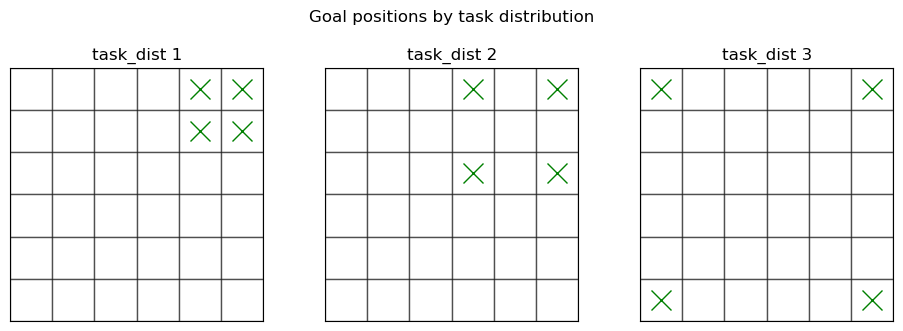

In [36]:
# visualise goal positions for each task distribution

n = len(task_dists)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (dist_id, goals) in zip(axes, task_dists.items()):
    for x in range(NUM_CELLS):
        for y in range(NUM_CELLS):
            ax.add_patch(Rectangle((x, y), 1, 1, facecolor="w", alpha=0.5, edgecolor="k"))

    for gx, gy in goals:
        ax.plot(gx + 0.5, NUM_CELLS - gy - 1 + 0.5, "gx", markersize=14, zorder=5)

    ax.set_xlim(0, NUM_CELLS)
    ax.set_ylim(NUM_CELLS, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"task_dist {dist_id}")

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle("Goal positions by task distribution", y=1.02)
fig.tight_layout()
plt.show()


In [37]:
# setting up the detection object
# Protocol matches exp9 (CheetahVel): Detect.lwe on SARS, REFERENCE_NUM=100,
# L2-normalize embeddings, then 1-cos pairwise. Discrete actions → one_hot=True.
OBS_DIM = 2
ACTION_DIM = 5
REFERENCE_NUM = 100
VIZ = False

# Shared with exp9 for cross-env comparison:
PCA_DIM = 8                 # PCA target dim
PAIRWISE_SUBSET_SIZE = 4    # match #goals per GridNavi TD (cheetah has 8)

detect = Detect(
    reference_num=REFERENCE_NUM,
    input_dim=OBS_DIM,
    action_dim=ACTION_DIM,
    num_samples=N,
    sars_flag=True,
    one_hot=True,  # discrete GridNavi actions
)
detect.set_reference(OBS_DIM, REFERENCE_NUM, ACTION_DIM)
print("reference shape", tuple(detect.ref.shape), "(expect N_ref × (2+5+1+2)=10)")
print(f"PCA_DIM={PCA_DIM} (set the same value in exp9 for cross-env comparison)")

reference shape (100, 10) (expect N_ref × (2+5+1+2)=10)
PCA_DIM=8 (set the same value in exp9 for cross-env comparison)


In [38]:
# Compute each task's WTE/LWE once (same Detect.lwe path as exp9), cache by TD.
# Then: between-TD cosine on mean embeddings (raw WTE).

embeddings_by_dist = {}  # dist_id -> list of 1d embeddings
goals_by_dist = {}
rows, labels, goals = [], [], []

for dist_id, task_dist in task_dists.items():
    out_dir = DATA_ROOT / f"task_dist{dist_id}"
    embeddings = []
    for goal in task_dist:
        sar = np.load(out_dir / f"goal_{goal[0]}_{goal[1]}.npy")
        embedding = np.asarray(detect.lwe(sar, ACTION_DIM)).ravel()
        embeddings.append(embedding)
        rows.append(embedding)
        labels.append(dist_id)
        goals.append(goal)
        if VIZ:
            print(f"--- dist {dist_id} goal={goal} sar={sar.shape} emb[:5]={embedding[:5]} ---")
    embeddings_by_dist[dist_id] = embeddings
    goals_by_dist[dist_id] = list(task_dist)

X = np.stack(rows)
labels = np.asarray(labels)
print(f"cached {len(rows)} task embeddings, raw dim={X.shape[1]}")

mean_embeddings = [np.mean(np.stack(embeddings_by_dist[d]), axis=0) for d in embeddings_by_dist]
dist_ids = list(embeddings_by_dist.keys())
V = np.stack(mean_embeddings)
V = V / np.clip(np.linalg.norm(V, axis=1, keepdims=True), 1e-12, None)
D = 1.0 - (V @ V.T)
df_mean = (
    pd.DataFrame(D, index=dist_ids, columns=dist_ids)
    .rename_axis("dist")
    .reset_index()
)
print("cosine distances between mean embeddings (raw WTE):")
display(df_mean.round(4))


cached 12 task embeddings, raw dim=1000
cosine distances between mean embeddings (raw WTE):


,dist,1,2,3
0,1,0.0000,0.0133,0.0156
1,2,0.0133,0.0000,0.0184
2,3,0.0156,0.0184,0.0000


In [39]:
# Within-TD mean pairwise on raw WTE.
# d_all: all pairs in the TD.  d_matched: fair vs cheetah (subset size =
# PAIRWISE_SUBSET_SIZE; no-op here since each grid TD already has 4 goals).
rows_within = []
for dist_id, embs in embeddings_by_dist.items():
    rows_within.append({
        "dist": dist_id,
        "n_tasks": len(embs),
        "d_all": mean_pairwise_cosine_distance(embs),
        "d_matched": mean_pairwise_matched(embs, PAIRWISE_SUBSET_SIZE),
    })
df_within = pd.DataFrame(rows_within)
print(f"raw WTE within-TD pairwise (matched subset_size={PAIRWISE_SUBSET_SIZE}):")
display(df_within.round(4))


raw WTE within-TD pairwise (matched subset_size=4):


,dist,n_tasks,d_all,d_matched
0,1,4,0.0588,0.0588
1,2,4,0.0558,0.0558
2,3,4,0.0517,0.0517


fair PCA corpus: 12 tasks (4/TD)  1000 → 8  var_sum=0.8456
PCA within-TD pairwise (fair: 4 tasks/TD, dim=8):


,dist,n_tasks,d_matched,pca_dim
0,1,4,1.1615,8
1,2,4,1.1176,8
2,3,4,0.9677,8


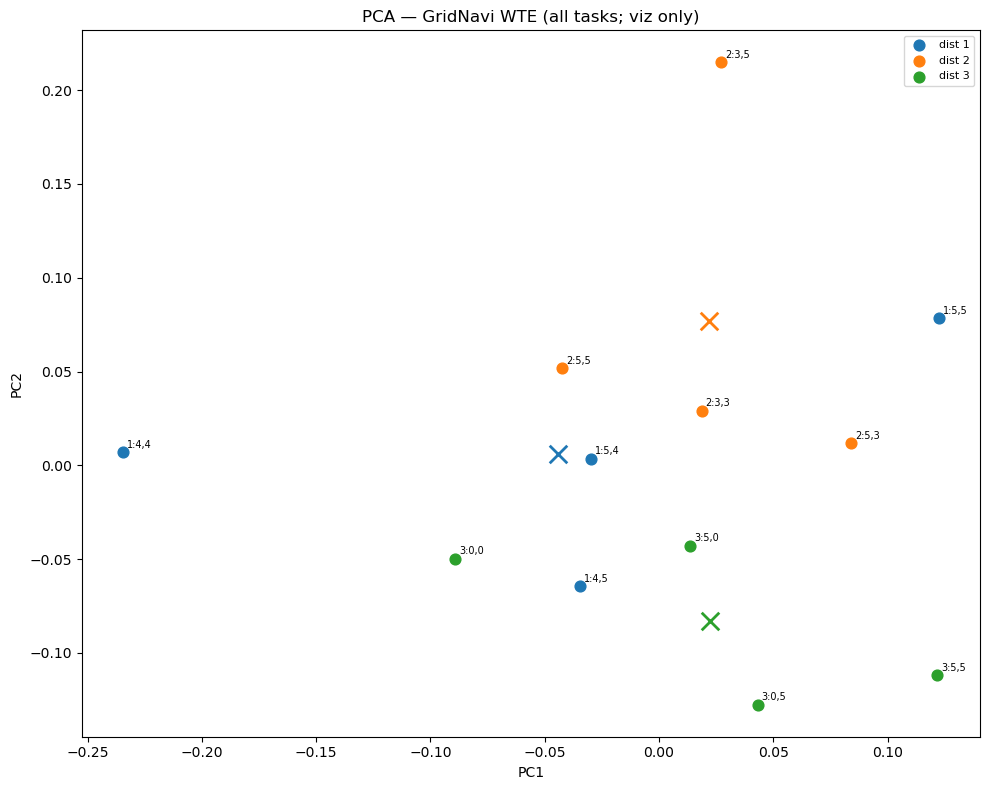

In [40]:
# Fair PCA comparison vs exp9:
# 1) Keep exactly PAIRWISE_SUBSET_SIZE tasks per TD (evenly spaced) so both
#    envs contribute the same #points/TD to the PCA fit and pairwise stats.
# 2) Fit PCA_DIM on that matched corpus, then within-TD mean pairwise on Z.
# Full-data PCA (all tasks) is still used for the scatter plot below.

fair_rows, fair_labels, fair_goals = [], [], []
for dist_id, embs in embeddings_by_dist.items():
    idxs = evenly_spaced_indices(len(embs), PAIRWISE_SUBSET_SIZE)
    g_list = goals_by_dist[dist_id]
    for i in idxs:
        fair_rows.append(embs[i])
        fair_labels.append(dist_id)
        fair_goals.append(g_list[i])

X_fair = np.stack(fair_rows)
labels_fair = np.asarray(fair_labels)
X_fair_n = X_fair / np.clip(np.linalg.norm(X_fair, axis=1, keepdims=True), 1e-12, None)

pca_dim_eff = min(X_fair.shape[0] - 1, X_fair.shape[1], PCA_DIM)
if pca_dim_eff < PCA_DIM:
    print(f"WARNING: PCA_DIM={PCA_DIM} > max feasible {pca_dim_eff}; using {pca_dim_eff}")

pca_fair = PCA(n_components=pca_dim_eff, random_state=0)
Z_fair = pca_fair.fit_transform(X_fair_n)
print(
    f"fair PCA corpus: {len(fair_rows)} tasks "
    f"({PAIRWISE_SUBSET_SIZE}/TD)  {X_fair.shape[1]} → {pca_dim_eff}  "
    f"var_sum={pca_fair.explained_variance_ratio_.sum():.4f}"
)

z_fair_by_dist = {d: [] for d in embeddings_by_dist}
for z, d in zip(Z_fair, labels_fair):
    z_fair_by_dist[int(d)].append(z)

df_within_pca = pd.DataFrame({
    "dist": list(z_fair_by_dist.keys()),
    "n_tasks": [len(v) for v in z_fair_by_dist.values()],
    "d_matched": [mean_pairwise_cosine_distance(v) for v in z_fair_by_dist.values()],
    "pca_dim": pca_dim_eff,
})
print(f"PCA within-TD pairwise (fair: {PAIRWISE_SUBSET_SIZE} tasks/TD, dim={pca_dim_eff}):")
display(df_within_pca.round(4))

# Scatter: PCA on *all* tasks (viz only; not used for the fair d table above)
X_n = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)
pca_viz = PCA(n_components=2, random_state=0)
Z = pca_viz.fit_transform(X_n)

fig, ax = plt.subplots(figsize=(10, 8))
for dist_id in sorted(set(labels.tolist())):
    mask = labels == dist_id
    sc = ax.scatter(Z[mask, 0], Z[mask, 1], s=60, label=f"dist {dist_id}")
    color = sc.get_facecolors()[0]
    ax.scatter(
        Z[mask, 0].mean(), Z[mask, 1].mean(),
        s=160, marker="x", linewidths=2, c=[color],
    )
for (x, y), g, d in zip(Z, goals, labels):
    ax.annotate(f"{d}:{g[0]},{g[1]}", (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("PCA — GridNavi WTE (all tasks; viz only)")
ax.legend(fontsize=8)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
fig.tight_layout()
plt.show()


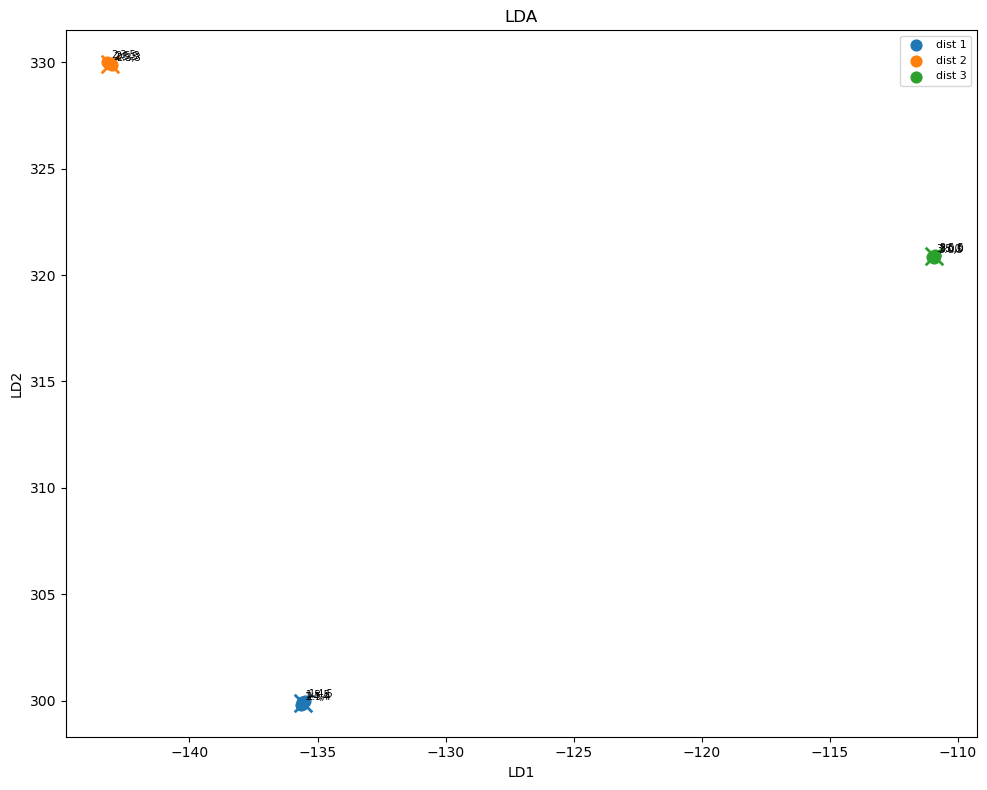

In [41]:
# LDA visualization of task embeddings


n_classes = len(np.unique(labels))
n_components = min(2, n_classes - 1)
# shrinkage helps when dim (800) >> n_samples (~24);
# eigen (not lsqr) supports transform() for 2D projection
lda = LinearDiscriminantAnalysis(
    n_components=n_components, solver="eigen", shrinkage="auto"
)
Z_lda = lda.fit_transform(X_n, labels)

fig, ax = plt.subplots(figsize=(10, 8))
for dist_id in sorted(set(labels.tolist())):
    mask = labels == dist_id
    sc = ax.scatter(
        Z_lda[mask, 0], Z_lda[mask, 1], s=60, marker="o", label=f"dist {dist_id}",
    )
    color = sc.get_facecolors()[0]
    ax.scatter(
        Z_lda[mask, 0].mean(),
        Z_lda[mask, 1].mean(),
        s=160,
        marker="x",
        linewidths=2,
        c=[color],
    )
for (x, y), g, d in zip(Z_lda, goals, labels):
    ax.annotate(f"{d}:{g[0]},{g[1]}", (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("LDA")
ax.legend(fontsize=8)
ax.set_xlabel("LD1")
ax.set_ylabel("LD2" if n_components == 2 else "")
fig.tight_layout()
plt.show()


## `run_exp.sh` eval returns (RNN+HN ablations on GridNavi TaskDist 1–3)

TensorBoard logs from `bash_scripts/run_exp.sh` live under `logs_gridworld/`:
`logs_GridNavi-TaskDist{k}-v0/grid_td{k}_rnn_{full,head,film}_*/events.out.tfevents.*`

The cells below read the **Meta-Episode Return** scalar directly from those event files (Step = env frames) and plot full vs head vs FiLM per task distribution, mirroring the CheetahVel section in `exp9.ipynb`.

In [42]:
# Load run_exp.sh Meta-Episode Return scalars from TensorBoard event files
import re

from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

GRID_LOG_ROOT = CODE_DIR / "logs_gridworld"
METHOD_ORDER = ("full", "head", "film")
METHOD_COLORS = {"full": "C0", "head": "C1", "film": "C2"}
GRID_TDS = (1, 2, 3)
RETURN_TAG = "Meta-Episode Return"


def load_grid_returns(log_root: Path = GRID_LOG_ROOT):
    """Return {(td, method): DataFrame[Step, Value, frames_m]} from TB logs."""
    out = {}
    for td in GRID_TDS:
        for method in METHOD_ORDER:
            runs = sorted(
                (log_root / f"logs_GridNavi-TaskDist{td}-v0").glob(
                    f"grid_td{td}_rnn_{method}_*"
                )
            )
            runs = [r for r in runs if r.is_dir()]
            if not runs:
                print(f"TD{td} {method}: no run found under {log_root}")
                continue
            run_dir = runs[-1]  # latest if re-run
            ea = EventAccumulator(str(run_dir))
            ea.Reload()
            if RETURN_TAG not in ea.Tags()["scalars"]:
                raise KeyError(f"{RETURN_TAG!r} not in {run_dir}; tags={ea.Tags()['scalars']}")
            vals = ea.Scalars(RETURN_TAG)
            df = pd.DataFrame(
                [(v.step, v.value) for v in vals], columns=["Step", "Value"]
            )
            df["frames_m"] = df["Step"] / 1e6
            df["method"] = method
            df["td"] = td
            df["source"] = run_dir.name
            out[(td, method)] = df
            print(
                f"TD{td} {method:5s}  n={len(df):3d}  "
                f"frames={df['Step'].iloc[-1]/1e6:.2f}M  "
                f"final={df['Value'].iloc[-1]:.1f}  run={run_dir.name}"
            )
    return out


grid_returns = load_grid_returns()

# Summary per (TD, method): final quality + learning-curve average (AUC/step)
_trapz = getattr(np, "trapezoid", np.trapz)
_summary_rows = []
for (td, method), df in sorted(grid_returns.items()):
    steps = df["Step"].to_numpy(dtype=float)
    y = df["Value"].to_numpy(dtype=float)
    last_mask = steps >= steps[-1] * 0.9
    _summary_rows.append(
        {
            "td": td,
            "method": method,
            "n_evals": len(df),
            "frames_M": steps[-1] / 1e6,
            "best": y.max(),
            "final": y[-1],
            "last_10pct_mean": y[last_mask].mean(),
            "auc_mean": _trapz(y, steps) / (steps[-1] - steps[0]),
        }
    )
df_grid_summary = pd.DataFrame(_summary_rows)
print("\nGridworld summary (Meta-Episode Return):")
display(df_grid_summary.round(2))

# Full/head/film gaps on last-10% mean, alongside PCA WTE diversity if computed above
_gap_rows = []
_pca_d = {}
if "df_within_pca" in globals():
    _pca_d = dict(zip(df_within_pca["dist"], df_within_pca["d_matched"]))
for td in GRID_TDS:
    vals = {
        m: df_grid_summary.loc[
            (df_grid_summary["td"] == td) & (df_grid_summary["method"] == m),
            "last_10pct_mean",
        ].iloc[0]
        for m in METHOD_ORDER
        if ((td, m) in grid_returns)
    }
    if len(vals) == 3:
        _gap_rows.append(
            {
                "td": td,
                "pca_d_matched": _pca_d.get(td, np.nan),
                "full_minus_head": vals["full"] - vals["head"],
                "full_minus_film": vals["full"] - vals["film"],
                "film_minus_head": vals["film"] - vals["head"],
            }
        )
df_grid_gaps = pd.DataFrame(_gap_rows)
print("Method gaps (last-10% mean) vs PCA WTE d_matched:")
display(df_grid_gaps.round(3))

TD1 full   n=835  frames=4.00M  final=63.2  run=grid_td1_rnn_full_73__19:10_19:16:12_62046
TD1 head   n=835  frames=4.00M  final=63.4  run=grid_td1_rnn_head_73__19:10_20:35:29_6c904
TD1 film   n=835  frames=4.00M  final=64.7  run=grid_td1_rnn_film_73__19:10_21:56:57_50a8b
TD2 full   n=835  frames=4.00M  final=62.1  run=grid_td2_rnn_full_73__19:10_15:27:23_a5485
TD2 head   n=835  frames=4.00M  final=62.8  run=grid_td2_rnn_head_73__19:10_16:45:59_80ef
TD2 film   n=835  frames=4.00M  final=64.3  run=grid_td2_rnn_film_73__19:10_18:00:27_121ef
TD3 full   n=835  frames=4.00M  final=56.4  run=grid_td3_rnn_full_73__19:10_11:37:33_51158
TD3 head   n=835  frames=4.00M  final=49.5  run=grid_td3_rnn_head_73__19:10_12:57:17_6918b
TD3 film   n=835  frames=4.00M  final=55.5  run=grid_td3_rnn_film_73__19:10_14:11:35_1541b

Gridworld summary (Meta-Episode Return):


,td,method,n_evals,frames_M,best,final,last_10pct_mean,auc_mean
0,1,film,835,4.0,66.80,64.67,63.45,62.43
1,1,full,835,4.0,66.80,63.22,61.23,61.78
2,1,head,835,4.0,66.87,63.43,63.03,60.62
3,2,film,835,4.0,67.42,64.26,63.99,61.88
4,2,full,835,4.0,67.01,62.06,63.01,61.04
5,2,head,835,4.0,67.90,62.81,63.36,61.43
6,3,film,835,4.0,62.74,55.46,55.98,52.11
7,3,full,835,4.0,62.06,56.42,56.43,52.75
8,3,head,835,4.0,61.09,49.54,55.80,51.93


Method gaps (last-10% mean) vs PCA WTE d_matched:


,td,pca_d_matched,full_minus_head,full_minus_film,film_minus_head
0,1,1.161,-1.804,-2.220,0.416
1,2,1.118,-0.349,-0.976,0.627
2,3,0.968,0.630,0.452,0.178


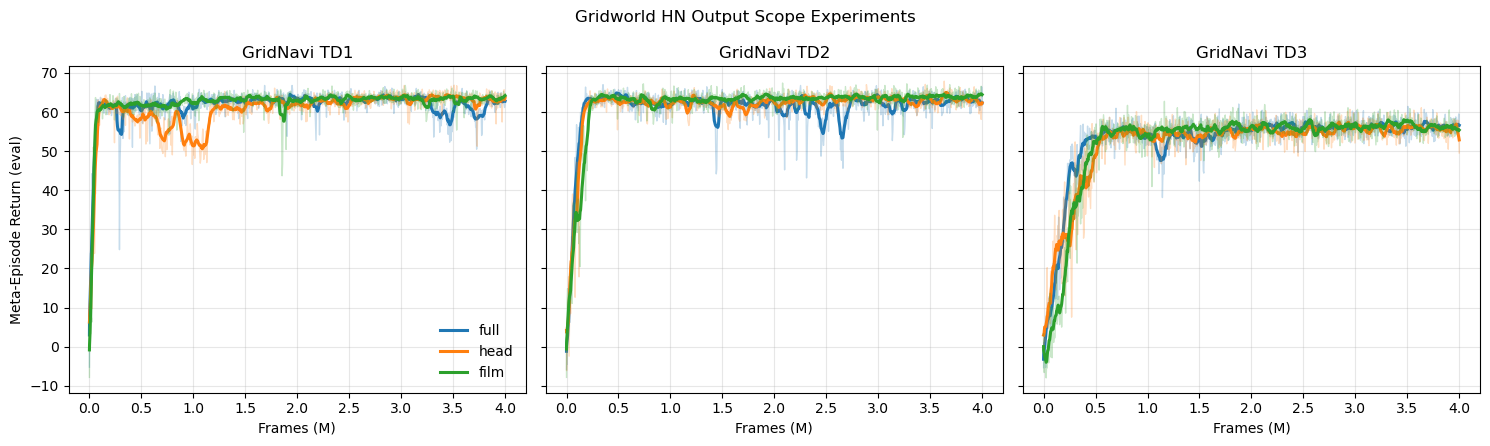

In [43]:
def smooth_series(y, window=11):
    """Centered rolling mean; odd window preferred (same as exp9)."""
    y = np.asarray(y, dtype=float)
    if window < 2 or len(y) < window:
        return y
    ker = np.ones(window) / window
    pad = window // 2
    yp = np.pad(y, (pad, pad), mode="edge")
    return np.convolve(yp, ker, mode="valid")


def plot_grid_returns(returns_dict, smooth=11, ylim=None):
    """One panel per GridNavi TD; full / head / film in each (mirrors exp9)."""
    fig, axes = plt.subplots(
        1, len(GRID_TDS), figsize=(5 * len(GRID_TDS), 4.5), sharey=True
    )
    axes = np.atleast_1d(axes)
    for ax, td in zip(axes, GRID_TDS):
        for method in METHOD_ORDER:
            if (td, method) not in returns_dict:
                continue
            df = returns_dict[(td, method)]
            x = df["frames_m"].to_numpy()
            y = df["Value"].to_numpy()
            color = METHOD_COLORS[method]
            ax.plot(x, y, color=color, alpha=0.25, linewidth=1)
            ax.plot(x, smooth_series(y, smooth), color=color, linewidth=2.2, label=method)
        ax.set_title(f"GridNavi TD{td}")
        ax.set_xlabel("Frames (M)")
        ax.grid(alpha=0.3)
        if ylim is not None:
            ax.set_ylim(*ylim)
    axes[0].set_ylabel("Meta-Episode Return (eval)")
    axes[0].legend(frameon=False)
    fig.suptitle("Gridworld HN Output Scope Experiments")
    fig.tight_layout()
    plt.show()


# Full scale: all three TDs side by side (raw faint + smoothed bold)
plot_grid_returns(grid_returns)

## HN weight divergence (`run_exp.sh`, GridNavi TaskDist 1–3)

Same runs as above. Scalar `hn_weight_div/mean_pairwise_l2` = mean pairwise L2 between per-goal mean **actor** weights generated by the hypernetwork (critic excluded; logged every 500 iterations, TB step = iteration). Higher = more task-specific policy weights. Plotted per TD for full vs head vs FiLM, mirroring the return panels.

In [44]:
# Load HN weight-divergence scalars from the same TensorBoard runs
import json

HNDIV_TAG = "hn_weight_div/mean_pairwise_l2"


def load_grid_hndiv(log_root: Path = GRID_LOG_ROOT):
    """Return {(td, method): DataFrame[Step(iter), Value, frames_m]}.

    TB step for this tag is the training iteration; frames_m is reconstructed
    as iter * num_processes * policy_num_steps from each run's config.json
    (16 * 60 = 960 frames/iter for run_exp.sh).
    """
    out = {}
    for td in GRID_TDS:
        for method in METHOD_ORDER:
            runs = sorted(
                (log_root / f"logs_GridNavi-TaskDist{td}-v0").glob(
                    f"grid_td{td}_rnn_{method}_*"
                )
            )
            runs = [r for r in runs if r.is_dir()]
            if not runs:
                print(f"TD{td} {method}: no run found under {log_root}")
                continue
            run_dir = runs[-1]
            cfg = json.loads((run_dir / "config.json").read_text())
            frames_per_iter = int(cfg["num_processes"]) * int(cfg["policy_num_steps"])
            ea = EventAccumulator(str(run_dir))
            ea.Reload()
            if HNDIV_TAG not in ea.Tags()["scalars"]:
                print(f"TD{td} {method}: {HNDIV_TAG!r} missing (log_hn_weight_div off?)")
                continue
            vals = ea.Scalars(HNDIV_TAG)
            df = pd.DataFrame(
                [(v.step, v.value) for v in vals], columns=["Step", "Value"]
            )
            df["frames_m"] = df["Step"] * frames_per_iter / 1e6
            df["method"] = method
            df["td"] = td
            df["source"] = run_dir.name
            out[(td, method)] = df
            print(
                f"TD{td} {method:5s}  n={len(df):2d}  iters={df['Step'].iloc[0]}-{df['Step'].iloc[-1]}  "
                f"final={df['Value'].iloc[-1]:.2f}  max={df['Value'].max():.2f}  run={run_dir.name}"
            )
    return out


grid_hndiv = load_grid_hndiv()

df_grid_hndiv = pd.DataFrame([
    {
        "td": td,
        "method": method,
        "n_logs": len(df),
        "final": df["Value"].iloc[-1],
        "max": df["Value"].max(),
        "mean": df["Value"].mean(),
    }
    for (td, method), df in sorted(grid_hndiv.items())
])
print("\nHN weight divergence summary (mean pairwise L2):")
display(df_grid_hndiv.round(2))

TD1 full   n= 8  iters=500-4000  final=4.55  max=4.55  run=grid_td1_rnn_full_73__19:10_19:16:12_62046
TD1 head   n= 8  iters=500-4000  final=0.79  max=1.07  run=grid_td1_rnn_head_73__19:10_20:35:29_6c904
TD1 film   n= 8  iters=500-4000  final=2.41  max=2.41  run=grid_td1_rnn_film_73__19:10_21:56:57_50a8b
TD2 full   n= 8  iters=500-4000  final=5.53  max=6.89  run=grid_td2_rnn_full_73__19:10_15:27:23_a5485
TD2 head   n= 8  iters=500-4000  final=1.89  max=2.16  run=grid_td2_rnn_head_73__19:10_16:45:59_80ef
TD2 film   n= 8  iters=500-4000  final=15.63  max=16.40  run=grid_td2_rnn_film_73__19:10_18:00:27_121ef
TD3 full   n= 8  iters=500-4000  final=5.84  max=6.46  run=grid_td3_rnn_full_73__19:10_11:37:33_51158
TD3 head   n= 8  iters=500-4000  final=1.74  max=2.35  run=grid_td3_rnn_head_73__19:10_12:57:17_6918b
TD3 film   n= 8  iters=500-4000  final=12.32  max=12.32  run=grid_td3_rnn_film_73__19:10_14:11:35_1541b

HN weight divergence summary (mean pairwise L2):


,td,method,n_logs,final,max,mean
0,1,film,8,2.41,2.41,1.48
1,1,full,8,4.55,4.55,2.64
2,1,head,8,0.79,1.07,0.92
3,2,film,8,15.63,16.40,12.69
4,2,full,8,5.53,6.89,5.10
5,2,head,8,1.89,2.16,1.95
6,3,film,8,12.32,12.32,9.45
7,3,full,8,5.84,6.46,5.28
8,3,head,8,1.74,2.35,1.95


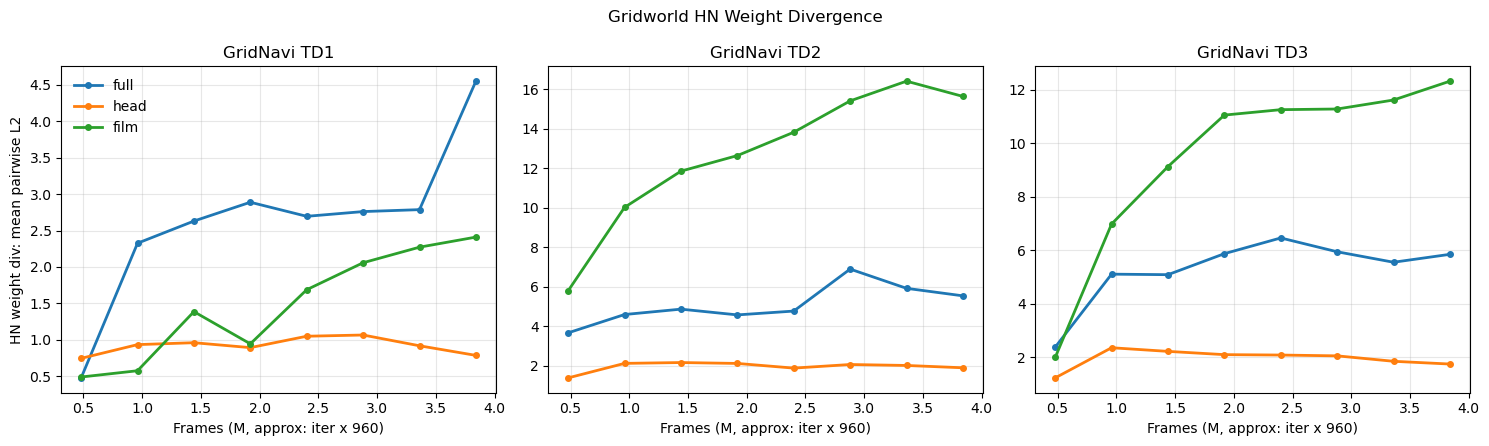

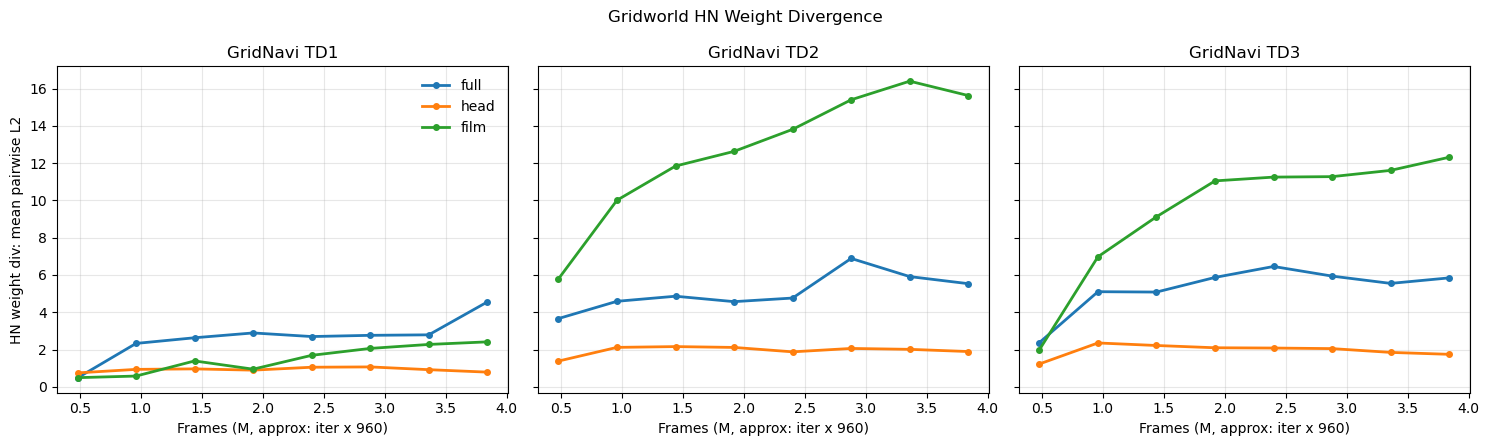

In [45]:
def plot_grid_hndiv(hndiv_dict, sharey=False):
    """One panel per TD; full / head / film HN weight divergence (mirrors returns)."""
    fig, axes = plt.subplots(
        1, len(GRID_TDS), figsize=(5 * len(GRID_TDS), 4.5), sharey=sharey
    )
    axes = np.atleast_1d(axes)
    for ax, td in zip(axes, GRID_TDS):
        for method in METHOD_ORDER:
            if (td, method) not in hndiv_dict:
                continue
            df = hndiv_dict[(td, method)]
            # Only ~8 logged points (every 500 iters) -> markers, no smoothing
            ax.plot(
                df["frames_m"], df["Value"], "o-",
                color=METHOD_COLORS[method], linewidth=2, markersize=4, label=method,
            )
        ax.set_title(f"GridNavi TD{td}")
        ax.set_xlabel("Frames (M, approx: iter x 960)")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("HN weight div: mean pairwise L2")
    axes[0].legend(frameon=False)
    fig.suptitle("Gridworld HN Weight Divergence")
    fig.tight_layout()
    plt.show()


# Per-TD y-scales: FiLM divergence on TD2/TD3 is ~3x full, ~8x head
plot_grid_hndiv(grid_hndiv, sharey=False)

# Shared y-scale version for direct cross-TD magnitude comparison
plot_grid_hndiv(grid_hndiv, sharey=True)